# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [43]:
from datetime import datetime, timedelta
import math
import time

**Create a new datetime object**

In [44]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [45]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [46]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [47]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [48]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [49]:
help(date1.__add__)

Help on method-wrapper:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [50]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [51]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [52]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [53]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [54]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [55]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [56]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [57]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

## step one 

im making everything in the sentence lowercase do that words are not counted seperately 

In [58]:
vocabulary = sorted(set(allText_noPunct.lower().split()))
print(vocabulary)

['and', 'fall', 'likes', 'max', 'sam', 'winter']


## step two
splitting things into words and count how often each term appears

In [59]:
docNew = documents[0]
words1 = docNew.translate(str.maketrans("", "", string.punctuation)).lower().split()
print(words1)

vector = [words1.count(word) for word in vocabulary]
print(vector)

['max', 'likes', 'sam']
[0, 0, 1, 1, 1, 0]


## Step three 

Now do this step for every part of the documents and for the query

In [60]:
Dvectors =[]
for docNew in documents: 
    words1 = docNew.translate(str.maketrans("", "", string.punctuation)).lower().split()
    vector = [words1.count(word) for word in vocabulary]
    Dvectors.append(vector)

queryWords = query.translate(str.maketrans("", "", string.punctuation)).lower().split()
queryVector = [queryWords.count(word) for word in vocabulary]

print(Dvectors)
print(queryVector)

[[0, 0, 1, 1, 1, 0], [0, 0, 1, 1, 1, 0], [1, 0, 0, 1, 1, 0], [0, 1, 1, 0, 0, 1]]
[0, 0, 1, 0, 1, 1]


## step four 

now after getting all of the vectors for the list, i have to calculate the simularity. 

(a x b)/(||a|| x ||b||)

In [61]:
d1 = Dvectors[0]
product = sum(a*b for a, b in zip(d1, queryVector))
D1norm = math.sqrt(sum(a**2 for a in d1))
Qnorm = math.sqrt(sum(b**2 for b in queryVector))

similarity = product / (D1norm * Qnorm)
print(similarity)



0.6666666666666667


## step 5 
now time to loop through all of them!!

In [62]:

silimarities = []
for vector in Dvectors:
    product = sum(a*b for a, b in zip(vector, queryVector))
    norm = math.sqrt(sum(a**2 for a in vector)) * Qnorm
    similarity = (product/norm)
    silimarities.append(similarity)


print(silimarities)

[0.6666666666666667, 0.6666666666666667, 0.33333333333333337, 0.6666666666666667]


## final 
based on this, d1, d2, and d4 are all tied because each one shares two terms! 

<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [63]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(url, sep='\t')

df.head()

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)>

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [ ]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [ ]:
columns=["country", "country_code", "wiki", 
         "page_id", "article", "qid", "pageviews"]

df = pd.read_csv(io.StringIO(response.text), sep='\t', names=columns, header=0)
df.head()

,country,country_code,wiki,page_id,article,qid,pageviews
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


## Task 3

For this dictionary, i chose high rated Kdramas, Cdramas, etc off of MyDramaList! I noticed that some titles have a suffix because the name of the show is shared with another tv show. (I also picked the shows that were talked about in my research papers!!!)

In [ ]:
shows = {"When_Life_Gives_You_Tangerines": 9.3,
         "Twinkling_Watermelon": 9.2,
         "Move_to_Heaven": 9.1,
         "Weak_Hero_Class_1": 9.1,
         "Flower_of_Evil_(South_Korean_TV_series)": 9.0,
         "Reply_1988": 9.0,
         "Mother_(South_Korean_TV_series)": 8.9,
         "The_Glory_(TV_series)": 8.9,
         "The_Good_Bad_Mother":8.9,
         "Study_Group_(TV_series)": 8.8,}

showTitles = list(shows.keys())
showTitles

['When_Life_Gives_You_Tangerines',
 'Twinkling_Watermelon',
 'Move_to_Heaven',
 'Weak_Hero_Class_1',
 'Flower_of_Evil_(South_Korean_TV_series)',
 'Reply_1988',
 'Mother_(South_Korean_TV_series)',
 'The_Glory_(TV_series)',
 'The_Good_Bad_Mother',
 'Study_Group_(TV_series)']

I'm going to try to do 1 day first before scraping the entire month

In [ ]:
oneDay = df[df["article"].isin(showTitles)]
print(len(oneDay))

for title in showTitles:
    print(title, (df["article"]== title).sum())

8
When_Life_Gives_You_Tangerines 3
Twinkling_Watermelon 2
Move_to_Heaven 0
Weak_Hero_Class_1 0
Flower_of_Evil_(South_Korean_TV_series) 0
Reply_1988 1
Mother_(South_Korean_TV_series) 0
The_Glory_(TV_series) 2
The_Good_Bad_Mother 0
Study_Group_(TV_series) 0


## step 4

collecting every day in september will be downloaded into a seperate tsv file, the URK ends in the date. I was thinking of building a loop using pd.date_range


In [64]:
Url = "https://analytics.wikimedia.org/published/datasets/country_project_page/"

daily = []
for date in pd.date_range("2026-09-01", "2026-09-30"):
    dateStr = date.strftime("%Y-%m-%d")
    response = requests.get(Url + dateStr + ".tsv", headers=headers)
    
    if response.status_code != 200:
        print("Could not get", response.status_code)
        continue

    response.encoding = 'utf-8'
    df = pd.read_csv(io.StringIO(response.text), sep='\t', header=None, names=columns)
    matches = df[df["article"].isin(showTitles)].copy()
    matches["date"]=dateStr
    daily.append(matches)

    print(dateStr, len(matches))
    time.sleep(1)

sept = pd.concat(daily)
sept.head()



2026-09-01 8
2026-09-02 8
2026-09-03 7
2026-09-04 9
2026-09-05 10
2026-09-06 13
2026-09-07 9
2026-09-08 10
2026-09-09 9
2026-09-10 11
2026-09-11 9
2026-09-12 11
2026-09-13 10
2026-09-14 8
2026-09-15 9
2026-09-16 7
2026-09-17 8
2026-09-18 9
2026-09-19 7
2026-09-20 10
2026-09-21 7
2026-09-22 7
2026-09-23 7
2026-09-24 7
2026-09-25 9
2026-09-26 8
2026-09-27 11
2026-09-28 10
2026-09-29 8
2026-09-30 9


,country,country_code,wiki,page_id,article,qid,pageviews,date
44599,United States,US,en.wikipedia,75066259,When_Life_Gives_You_Tangerines,Q117353211,332,2026-09-01
89681,United States,US,en.wikipedia,71359872,The_Glory_(TV_series),Q113197148,298,2026-09-01
109498,India,IN,en.wikipedia,78584079,Study_Group_(TV_series),Q131429579,97,2026-09-01
182020,United States,US,en.wikipedia,47975124,Reply_1988,Q19657395,212,2026-09-01
189986,India,IN,en.wikipedia,47975124,Reply_1988,Q19657395,102,2026-09-01


## Next dave to csv file!

In [65]:
sept.to_csv("wikimedia-sept.tsv", sep="\t", index=False)
print(len(sept))

265


## Total views 
i'm planning on grouping the rows by country and then add up the views. especially since a country can show up more than once for the same show i.e. english and indo wiki pages 

In [67]:
CountryViews = sept.groupby("country")["pageviews"].sum().sort_values(ascending=False)
print(len(CountryViews))
print(CountryViews.head(10))

7
country
United States     26282
India             23117
Philippines        1916
Canada             1454
United Kingdom      283
Malaysia            191
Singapore           185
Name: pageviews, dtype: int64


now i display on a graph!!

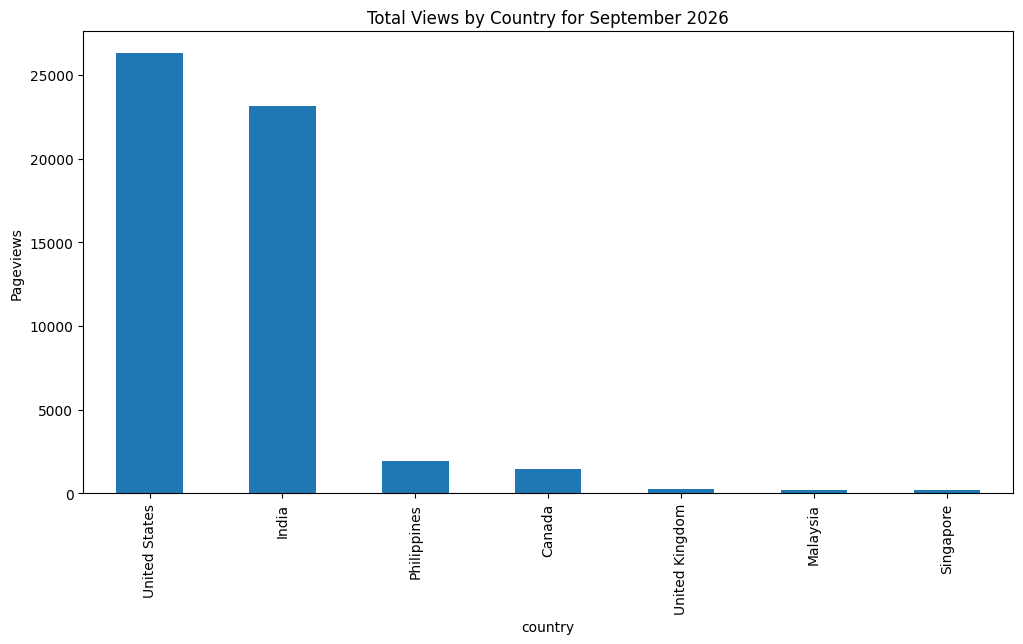

In [71]:
import matplotlib.pyplot as plt
CountryViews.plot(kind="bar", figsize=(12,6), title="Total Views by Country for September 2026")
plt.ylabel("Pageviews")
plt.show()

i guess im not sure why contries like korea did not pop up? I was rather surprised to see the Philippines and India pretty high up! I guess that could relate to the population density of the countries. 

## total views by shows
same idea as before but now we are going to group by articles and see which shows got the most views across all countries 

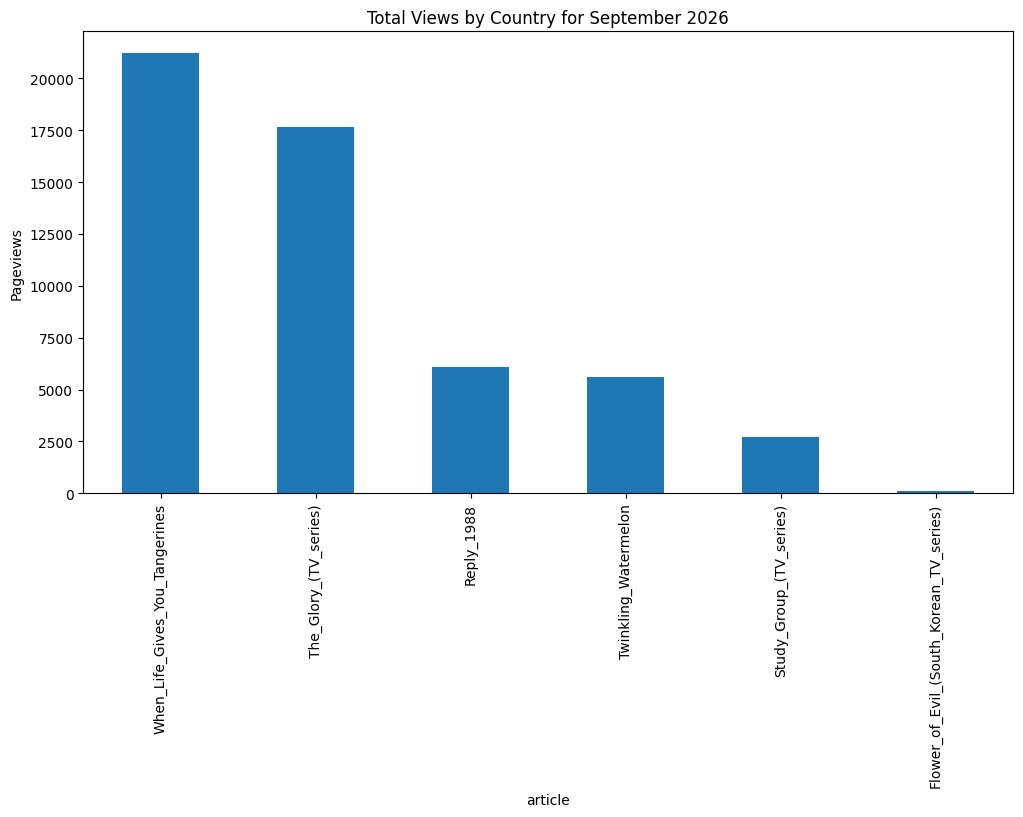

In [72]:
ShowViews = sept.groupby("article")["pageviews"].sum().sort_values(ascending=False)
ShowViews.plot(kind="bar", figsize=(12,6), title="Total Views by Country for September 2026")
plt.ylabel("Pageviews")
plt.show()

## Ratings and views? 

In [74]:
comp = pd.DataFrame({
    "total_views": ShowViews,
    "rating": pd.Series(shows),    
}).sort_values(by="total_views", ascending=False)

comp

,total_views,rating
When_Life_Gives_You_Tangerines,21206.0,9.3
The_Glory_(TV_series),17670.0,8.9
Reply_1988,6102.0,9.0
Twinkling_Watermelon,5623.0,9.2
Study_Group_(TV_series),2732.0,8.8
Flower_of_Evil_(South_Korean_TV_series),95.0,9.0
Mother_(South_Korean_TV_series),NaN,8.9
Move_to_Heaven,NaN,9.1
The_Good_Bad_Mother,NaN,8.9
Weak_Hero_Class_1,NaN,9.1


## Writeup 

1. The pages for my 10 shows were viewed in 7 countries in september, I think some of the other pages did not show up because they did not hit the 90 views per day threshold. We can see the views are extremely concentrated in the US and India followed far behind by the Philippines and Canada. India's position stands out espeically since its tied with the US, which suggests that Kdramas have a large audience there, which was bigger than I expected. I would assume that other countries read about these showd in their own language's Wikipedia under different titles so they might not show up, which can explain the gap in the missing shows 

2. When Life gives you tangerines and the flory dominate, with much larger totals than the others, Reply 1988, Twinkling Watermelon and Study Group got moderate attention and Flower of Evil barely made the cut. I think it was very surprising to see older Kdramas on here while newer ones like Mother, Move to Heaven, The good bad mother, etc did not each the 90 pageview threshold. 

3. by eyeballing the data, there is no strong relationship between rating and pageviews since my rating fall in a rather narrow range. Also release date likely matters more than others. Also rating refelcts how much viewrs liked a show while pageviews reflect how many people are curious about it, which in turn are very different things. Another thing is a 90 day threthhold hides smaller audiences completely, there could be a cult following for a show on a sub reddit and interact more on there verses looking at a wiki page